# 1. Import Packages:

In [1]:
import pandas as pd 
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from sklearn.impute import KNNImputer

In [2]:
# To check the environment:
import sys
print(sys.executable)

d:\DS Course\Job_P3\.venv\Scripts\python.exe


# 2. Read the File:

In [3]:
df=pd.read_csv("D:/DS Course/Job_P3/HR_Job_Placement_Dataset.csv")

# 3. Data Inspection:

In [4]:
#1. Check Row & Columns:(51500,26-25/10)
df.shape

(51500, 26)

In [5]:
#2. Column Names:
df.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status'],
      dtype='str')

In [6]:
# To set all cols to disp:
pd.set_option('display.max_columns',None)

In [7]:
df.sample(10)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
44550,33,Male,62.900942,59.328099,64.445295,Others,75.016604,72.362044,45.000000,54.455519,1,Yes,1,Willing,Not Relevant,1.000000,11.287031,Tier 3,Matched,Low,Not Required,15.0,No,6.0,Willing,Not Placed
19138,30,Male,73.361426,60.811703,73.760886,Others,68.833256,73.341512,55.029802,80.112002,2,Yes,3,Not Willing,NaN,5.706367,4.455244,Tier 2,Matched,Medium,Not Required,15.0,No,18.0,Willing,Placed
10198,27,Female,75.189539,77.178691,79.860737,Others,57.521453,74.586292,55.106592,79.391675,3,No,4,Willing,Relevant,3.846416,5.747688,Tier 2,Matched,High,Not Required,30.0,No,6.0,Willing,Not Placed
24162,31,Male,58.617829,75.801974,71.556909,Computer Science,47.046578,72.044395,49.677459,79.038065,0,No,3,NaN,Relevant,7.297517,3.000000,Tier 1,NaN,Low,Not Required,0.0,No,0.0,Not Willing,Not Placed
7321,28,Male,72.302789,72.595704,71.409887,Information Technology,49.906680,62.775130,58.993720,79.857106,1,No,1,Not Willing,Relevant,3.087405,9.308529,Tier 1,Matched,Low,Not Required,0.0,No,3.0,Willing,Not Placed
33381,23,Female,74.261031,66.207788,70.922466,Information Technology,70.303590,68.933572,81.072847,53.836852,2,No,0,NaN,NaN,5.049344,5.327301,Tier 2,Matched,Medium,Not Required,30.0,NaN,0.0,Willing,Not Placed
30125,27,Male,63.209195,80.790267,74.428140,Information Technology,63.969758,69.270222,61.337743,80.465297,2,yes,4,NaN,Not Relevant,4.420165,5.205771,Tier 3,NaN,Low,Not Required,NaN,NaN,0.0,Willing,Placed
31931,28,Male,NaN,67.446920,87.357002,Information Technology,63.966229,59.830881,61.680902,63.101207,1,No,2,Not Willing,NaN,5.820889,9.138279,Tier 3,Not Matched,Low,Not Required,0.0,No,0.0,NaN,Not Placed
1258,29,Female,58.040593,67.200901,87.025023,Mechanical,71.299224,40.000000,73.132182,83.778006,1,Yes,1,Not Willing,Relevant,2.407481,5.414986,Tier 1,Matched,Medium,Not Required,0.0,No,3.0,Not Willing,Placed
50900,29,Male,68.039522,71.506126,67.352962,Electronics,76.226868,63.634533,61.969182,77.109153,2,No,1,Not Willing,Not Relevant,3.733368,15.854531,Tier 3,Matched,Low,Required,60.0,No,0.0,Willing,Not Placed


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  str    
 14  r

# 4. Data Cleaning:

In [9]:
# Copy th dataframe: (51500, 26)
df1=df.copy()
df1.shape

(51500, 26)

*#1. Check Duplicate:*

In [10]:
# Check for Row-wise Duplicates:
df1.duplicated().sum()

np.int64(1376)

In [11]:
df1[df1.duplicated()]#to show the duplicated rows

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
50000,29,Male,82.777504,55.403494,72.608382,Computer Science,85.730203,72.426358,51.770110,97.577679,3,Yes,3,Willing,Not Relevant,2.098782,9.093150,Tier 2,Matched,Medium,Not Required,15.0,No,0.0,Not Willing,Placed
50001,27,male,54.905068,80.120543,77.037600,Computer Science,54.166158,61.548708,65.307474,66.014409,0,Yes,0,Not Willing,NaN,2.326030,7.292962,Tier 2,Matched,Low,Not Required,15.0,No,0.0,NaN,Not Placed
50003,21,Female,62.638945,60.735432,77.153040,Computer Science,59.987920,59.017158,56.717055,73.084570,0,No,2,Not Willing,NaN,1.024514,7.108719,Tier 1,Matched,Low,Not Required,0.0,No,0.0,Not Willing,Not Placed
50004,25,Male,59.360622,70.230456,85.377955,Mechanical,65.678132,83.774928,79.334052,80.443948,4,No,3,Not Willing,Not Relevant,5.159515,10.555169,Tier 1,Matched,Low,Required,60.0,No,0.0,Not Willing,Not Placed
50005,22,Female,72.019465,79.009356,67.887885,Others,56.213118,73.397254,48.806828,91.301263,1,No,3,Not Willing,Relevant,6.352580,7.938697,Tier 1,Matched,Low,Not Required,60.0,No,12.0,Willing,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51494,26,Female,69.562323,63.891266,75.931809,Computer Science,59.990409,51.169120,73.769113,68.913006,2,Yes,0,Not Willing,Relevant,7.258753,7.910303,Tier 2,NaN,Medium,Not Required,0.0,No,6.0,Not Willing,Not Placed
51495,24,Female,65.747180,72.063946,72.247881,Electronics,55.923057,73.208032,69.108895,63.992488,2,No,0,Not Willing,Not Relevant,1.874355,6.315211,Tier 1,Matched,Low,Required,0.0,No,3.0,NaN,Not Placed
51496,22,Male,61.921459,66.729203,55.000000,Others,69.525121,70.245612,54.959868,88.514232,0,Yes,1,Not Willing,Not Relevant,7.848456,8.655391,Tier 1,Matched,Medium,Not Required,60.0,No,0.0,Not Willing,Placed
51498,29,Female,77.327209,56.629227,69.735374,Mechanical,48.270078,61.171900,71.650243,76.318681,0,Yes,0,NaN,Relevant,7.027731,9.617279,Tier 2,Matched,Medium,Not Required,0.0,Yes,0.0,Willing,Not Placed


In [12]:
# Drop the rows with duplicate:
# .reset_index(drop=True) because extra rows attached during encoding
df1=df1.drop_duplicates(keep='first').reset_index(drop=True)

In [13]:
# After Drop Duplicates:row and col:(50124, 26)
print(f"dup:{df1.duplicated().sum()}")
print(f"row and col:{df1.shape}")

dup:0
row and col:(50124, 26)


In [14]:
df1

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50119,33,Male,59.202809,70.381922,64.194312,Computer Science,58.749055,70.892920,66.256945,64.288988,1,Yes,0,Not Willing,Not Relevant,5.440900,7.147591,Tier 3,Not Matched,Low,Not Required,0.0,No,0.0,Willing,Not Placed
50120,26,Female,59.085833,68.795821,82.025453,Mechanical,67.147475,67.903147,72.304220,70.019765,0,Yes,2,Not Willing,Relevant,3.756132,13.043249,Tier 1,Matched,Low,Required,90.0,No,0.0,NaN,Not Placed
50121,23,Male,66.290959,75.552994,66.761658,Others,64.135029,65.579632,68.462568,100.000000,1,No,2,Not Willing,Relevant,2.030042,16.062690,Tier 2,Matched,Low,Not Required,15.0,No,0.0,Not Willing,Not Placed
50122,24,Female,72.151163,63.397535,67.094174,Computer Science,60.228937,72.189740,89.993044,72.266721,2,Yes,3,NaN,Relevant,3.681501,8.604388,Tier 3,Matched,Low,Not Required,0.0,No,0.0,Willing,Placed


*#2. Data NULL Handling:*

In [15]:
#2.1 Get Count of NULL:
df1.isna().sum()

age_years                       0
gender                          0
ssc_percentage               2509
hsc_percentage               2006
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8242
relevant_experience          8199
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               5964
competition_level               0
bond_requirement                0
notice_period_days           1538
layoff_history               8259
employment_gap_months        1074
relocation_willingness       8247
status                          0
dtype: int64

In [16]:
#2.2. Get cols name with NULL:
df1.columns[df1.isna().any()]

Index(['ssc_percentage', 'hsc_percentage', 'career_switch_willingness',
       'relevant_experience', 'job_role_match', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness'],
      dtype='str')

#                                 Categorical Columns

In [17]:
#2.3 Get all CAT Cols with NULL

cat_cols = df1.select_dtypes(include=['str']).columns
df1[cat_cols].columns[df1[cat_cols].isna().any()]

Index(['career_switch_willingness', 'relevant_experience', 'job_role_match',
       'layoff_history', 'relocation_willingness'],
      dtype='str')

In [18]:
# career_switch_willingness- Groupwise cleaning

df1['career_switch_willingness']=(df1.groupby('degree_specialization')['career_switch_willingness']
                                                        .transform(lambda x:x.fillna(x.mode().iloc[0]
                                                                                     if not x.mode().empty
                                                                                     else 'unknown')))
df1['career_switch_willingness'].isna().sum()

np.int64(0)

In [19]:
df1['career_switch_willingness'].value_counts()

career_switch_willingness
Not Willing    35949
Willing        14175
Name: count, dtype: int64

In [20]:
# Imput through mode:relevant_experience,layoff_history
df1['relevant_experience']=df1['relevant_experience'].fillna(df1['relevant_experience'].mode()[0])
df1['layoff_history']=df1['layoff_history'].fillna(df1['layoff_history'].mode()[0])

In [21]:
df1[['relevant_experience','layoff_history']].isna().sum()

relevant_experience    0
layoff_history         0
dtype: int64

In [22]:
# relocation willingness Imputation through NUMPY:
reloc= df1['relocation_willingness'].isnull()

df1.loc[reloc,'relocation_willingness']=np.random.choice(
    ['Willing','Not Willing'],
    size=reloc.sum()
)

df1['relocation_willingness'].isnull().sum()

np.int64(0)

In [23]:
df1['relocation_willingness'].value_counts()

relocation_willingness
Willing        31188
Not Willing    18936
Name: count, dtype: int64

In [24]:
df1['job_role_match']=(df1.groupby('relevant_experience')['job_role_match']
                                                        .transform(lambda x:x.fillna(x.mode().iloc[0]
                                                                                     if not x.mode().empty
                                                                                     else 'unknown')))
df1['job_role_match'].isna().sum()

np.int64(0)

In [25]:
df1.columns[df1.isna().any()]

Index(['ssc_percentage', 'hsc_percentage', 'notice_period_days',
       'employment_gap_months'],
      dtype='str')

# Numerical Columns

<Axes: >

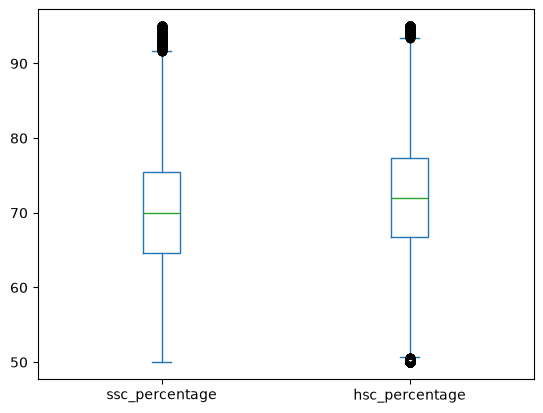

In [26]:
# Check for outliers : ssc_percentage
df1[['ssc_percentage','hsc_percentage']].plot(kind='box')

In [27]:
#Imputation through median values: ssc

med_ssc=df1['ssc_percentage'].median()
df1['ssc_percentage']=df1['ssc_percentage'].fillna(med_ssc)
df1['ssc_percentage'].isna().sum()

np.int64(0)

In [28]:
#Imputation through median values: hsc

med_hsc=df1['hsc_percentage'].median()
df1['hsc_percentage']=df1['hsc_percentage'].fillna(med_hsc)
df1['hsc_percentage'].isna().sum()

np.int64(0)

In [29]:
#Check data types in SSC %
df1['ssc_percentage'].dtype

dtype('float64')

In [30]:
# Check null in notice_period_days:
df1['notice_period_days'].isna().sum()

np.int64(1538)

In [31]:
# Impute through KNN method:

imputer=KNNImputer(n_neighbors=6)
df1['notice_period_days']=imputer.fit_transform(df1[['notice_period_days']]).astype(int)
df1['notice_period_days'].isna().sum()

np.int64(0)

In [32]:
print(df1['employment_gap_months'].isna().sum())
df1['employment_gap_months'].value_counts()

1074


employment_gap_months
0.0     25967
3.0     10152
6.0      7456
12.0     3952
18.0     1523
Name: count, dtype: int64

<Axes: ylabel='Density'>

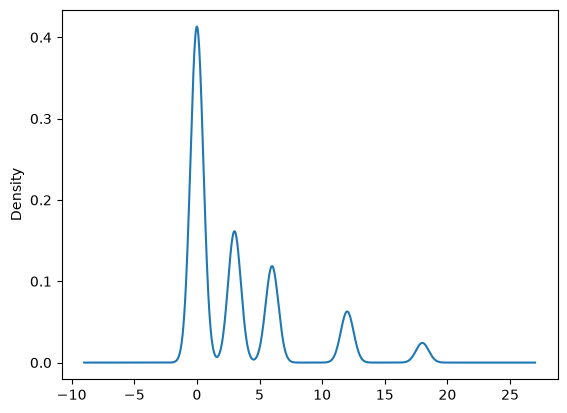

In [33]:
df1['employment_gap_months'].plot(kind='kde')

In [34]:
# IMPUTATION through Median: employment_gap_months

emp_med=df1['employment_gap_months'].median()

df1['employment_gap_months']=df1['employment_gap_months'].fillna(emp_med)
df1['employment_gap_months'].isna().sum()

np.int64(0)

*# After NULL HANDLING*

In [35]:
df1.isna().sum()

age_years                    0
gender                       0
ssc_percentage               0
hsc_percentage               0
degree_percentage            0
degree_specialization        0
technical_score              0
aptitude_score               0
communication_score          0
skills_match_percentage      0
certifications_count         0
internship_experience        0
years_of_experience          0
career_switch_willingness    0
relevant_experience          0
previous_ctc_lpa             0
expected_ctc_lpa             0
company_tier                 0
job_role_match               0
competition_level            0
bond_requirement             0
notice_period_days           0
layoff_history               0
employment_gap_months        0
relocation_willingness       0
status                       0
dtype: int64

In [36]:
df1

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0,No,0.0,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0,Yes,6.0,Not Willing,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0,No,3.0,Willing,Not Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50119,33,Male,59.202809,70.381922,64.194312,Computer Science,58.749055,70.892920,66.256945,64.288988,1,Yes,0,Not Willing,Not Relevant,5.440900,7.147591,Tier 3,Not Matched,Low,Not Required,0,No,0.0,Willing,Not Placed
50120,26,Female,59.085833,68.795821,82.025453,Mechanical,67.147475,67.903147,72.304220,70.019765,0,Yes,2,Not Willing,Relevant,3.756132,13.043249,Tier 1,Matched,Low,Required,90,No,0.0,Not Willing,Not Placed
50121,23,Male,66.290959,75.552994,66.761658,Others,64.135029,65.579632,68.462568,100.000000,1,No,2,Not Willing,Relevant,2.030042,16.062690,Tier 2,Matched,Low,Not Required,15,No,0.0,Not Willing,Not Placed
50122,24,Female,72.151163,63.397535,67.094174,Computer Science,60.228937,72.189740,89.993044,72.266721,2,Yes,3,Not Willing,Relevant,3.681501,8.604388,Tier 3,Matched,Low,Not Required,0,No,0.0,Willing,Placed


<Axes: >

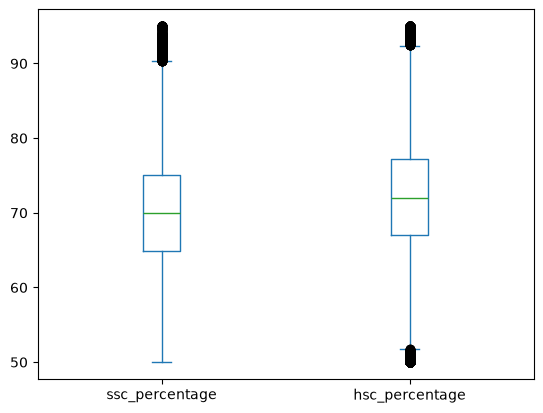

In [37]:
df1[['ssc_percentage','hsc_percentage']].plot(kind='box')

<Axes: ylabel='Density'>

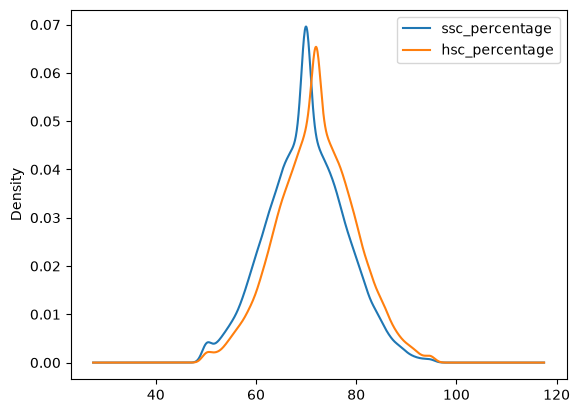

In [38]:
# Check Skewness:
df1[['ssc_percentage','hsc_percentage']].plot(kind='kde')

<Axes: ylabel='Density'>

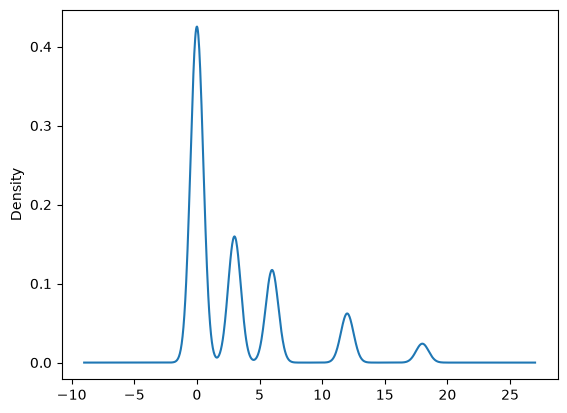

In [39]:
df1['employment_gap_months'].plot(kind='kde')

<Axes: ylabel='Density'>

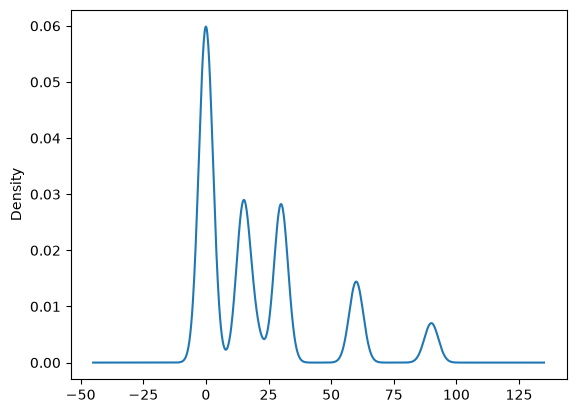

In [40]:
df1['notice_period_days'].plot(kind='kde')

In [41]:
df1.describe()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months
count,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000,50124.000000
mean,27.505726,70.012977,72.061840,74.005954,68.036581,63.993420,66.102068,73.941400,1.401065,1.493935,4.844926,8.002108,20.101349,2.993177
std,4.026713,7.776436,7.763087,6.947543,11.857251,9.914872,9.901965,11.801066,1.184953,1.375953,2.126617,3.137160,24.471993,4.406516
min,21.000000,50.000000,50.000000,55.000000,40.000000,40.000000,45.000000,45.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000
25%,24.000000,64.899464,66.968530,69.294051,59.948322,57.195219,59.256023,65.864353,1.000000,0.000000,3.323641,5.668812,0.000000,0.000000
50%,27.000000,69.978358,72.019567,73.991762,68.002681,63.950685,66.024739,74.001772,1.000000,1.000000,4.806979,7.856123,15.000000,0.000000
75%,31.000000,75.077571,77.145905,78.711869,76.066951,70.703499,72.837512,82.119869,2.000000,2.000000,6.297785,10.094009,30.000000,6.000000
max,34.000000,95.000000,95.000000,95.000000,100.000000,100.000000,100.000000,100.000000,8.000000,5.000000,13.844566,26.524634,90.000000,18.000000


*#3.Standardization*

In [42]:
df1.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status'],
      dtype='str')

In [43]:
cat_cols = df1.select_dtypes(include=['str']).columns
df1[cat_cols].columns

Index(['gender', 'degree_specialization', 'internship_experience',
       'career_switch_willingness', 'relevant_experience', 'company_tier',
       'job_role_match', 'competition_level', 'bond_requirement',
       'layoff_history', 'relocation_willingness', 'status'],
      dtype='str')

In [44]:
#3.1 Check gender, degree_ spec, internship_exp
df1['gender'].value_counts()

gender
Female    23701
Male      23416
female     1504
male       1503
Name: count, dtype: int64

In [45]:
# Standardize gender to title case:

df1['gender']=df1['gender'].str.title()

In [46]:
df1['gender'].value_counts()

gender
Female    25205
Male      24919
Name: count, dtype: int64

In [47]:
# degree_specialization has no change: 

df1[['degree_specialization','internship_experience']].value_counts()


degree_specialization   internship_experience
Others                  No                       5049
Information Technology  No                       4982
Computer Science        No                       4973
Electronics             No                       4950
Mechanical              No                       4948
Others                  Yes                      4612
Electronics             Yes                      4610
Information Technology  Yes                      4555
Mechanical              Yes                      4472
Computer Science        Yes                      4466
Others                   no                       280
Computer Science         no                       262
Electronics              no                       261
Mechanical               no                       258
Electronics             yes                       257
Information Technology   no                       253
                        yes                       242
Mechanical              yes         

In [48]:
# Clear the df1['internship_experience'] to TITLE case & REMOVE extra space:

df1['internship_experience']=df1['internship_experience'].str.title().str.strip()

In [49]:
df1[['degree_specialization','internship_experience']].value_counts()

degree_specialization   internship_experience
Others                  No                       5329
Computer Science        No                       5235
Information Technology  No                       5235
Electronics             No                       5211
Mechanical              No                       5206
Electronics             Yes                      4867
Others                  Yes                      4845
Information Technology  Yes                      4797
Mechanical              Yes                      4707
Computer Science        Yes                      4692
Name: count, dtype: int64

In [50]:
# career_switch_willingness & relevant_experience - CHECKING

df1[['career_switch_willingness','relevant_experience']].value_counts()

career_switch_willingness  relevant_experience
Not Willing                Relevant               24266
                           Not Relevant           11683
Willing                    Relevant                9530
                           Not Relevant            4645
Name: count, dtype: int64

In [51]:
# job_role_match, layoff_history,relocation_willingness- CHECKING

df1[['job_role_match','layoff_history', 'relocation_willingness']].value_counts()

job_role_match  layoff_history  relocation_willingness
Matched         No              Willing                   21298
                                Not Willing               12918
Not Matched     No              Willing                    6467
                                Not Willing                3904
Matched         Yes             Willing                    2683
                                Not Willing                1622
Not Matched     Yes             Willing                     740
                                Not Willing                 492
Name: count, dtype: int64

In [53]:
# company_tier -CHECKING- REMOVE extra space
df1['company_tier'].str.strip().value_counts()

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64

In [54]:
# 'competition_level','bond_requirement', 'status' -- CLEANED 
df1[['competition_level','bond_requirement', 'status']].value_counts()

competition_level  bond_requirement  status    
Low                Not Required      Not Placed    10792
Medium             Not Required      Not Placed     9926
High               Not Required      Not Placed     5868
Low                Not Required      Placed         5500
Medium             Not Required      Placed         5085
Low                Required          Not Placed     3441
Medium             Required          Not Placed     3119
High               Not Required      Placed         1993
                   Required          Not Placed     1804
Low                Required          Placed         1158
Medium             Required          Placed         1035
High               Required          Placed          403
Name: count, dtype: int64

*#4 Check Data Types*

In [55]:
df1[['gender', 'degree_specialization', 'internship_experience',
       'career_switch_willingness', 'relevant_experience', 'company_tier',
       'job_role_match', 'competition_level', 'bond_requirement',
       'layoff_history', 'relocation_willingness', 'status']].dtypes

gender                       str
degree_specialization        str
internship_experience        str
career_switch_willingness    str
relevant_experience          str
company_tier                 str
job_role_match               str
competition_level            str
bond_requirement             str
layoff_history               str
relocation_willingness       str
status                       str
dtype: object

In [56]:
df1[['age_years', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage',  'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count',  'years_of_experience',
       'previous_ctc_lpa','expected_ctc_lpa', 'notice_period_days',
        'employment_gap_months']].dtypes

age_years                    int64
ssc_percentage             float64
hsc_percentage             float64
degree_percentage          float64
technical_score            float64
aptitude_score             float64
communication_score        float64
skills_match_percentage    float64
certifications_count         int64
years_of_experience          int64
previous_ctc_lpa           float64
expected_ctc_lpa           float64
notice_period_days           int64
employment_gap_months      float64
dtype: object

In [57]:
df1.head(10)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,Yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0,No,0.0,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0,Yes,6.0,Not Willing,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0,No,3.0,Willing,Not Placed
5,33,Female,60.641768,66.151843,78.203455,Others,85.063940,46.293090,47.638858,78.307411,1,Yes,1,Not Willing,Relevant,4.918530,3.000000,Tier 2,Not Matched,Low,Not Required,60,No,0.0,Not Willing,Placed
6,25,Female,78.224191,69.578282,79.870959,Mechanical,85.168067,47.188328,70.348778,79.935956,1,Yes,1,Not Willing,Relevant,7.946910,7.114406,Tier 2,Matched,Low,Not Required,0,No,0.0,Not Willing,Placed
7,27,Female,69.978358,69.111350,75.430679,Others,75.672196,56.391743,76.383155,77.546335,0,Yes,3,Willing,Relevant,8.056013,3.103734,Tier 1,Matched,Medium,Not Required,0,No,0.0,Not Willing,Placed
8,30,Female,69.535754,78.757507,79.757543,Mechanical,78.282823,62.647484,81.629846,67.931840,3,Yes,2,Not Willing,Relevant,4.190206,3.000000,Tier 3,Matched,Low,Not Required,20,No,0.0,Not Willing,Placed
9,23,Female,70.972461,78.101606,72.767897,Mechanical,54.554258,61.055905,59.567957,95.125145,0,No,2,Willing,Relevant,5.925225,3.091102,Tier 1,Not Matched,High,Required,0,No,0.0,Willing,Not Placed


# 5. Save the Cleaned DATA:

In [59]:
df1.to_csv(r"D:\DS Course\Job_P3\placement_clean_data.csv",
           index=False,
               encoding="utf-8"
           )
           
print("Cleaned CSV saved successfully")

Cleaned CSV saved successfully


# 6. EDA

*#1 CORRELATION of Numeric Col:*

In [60]:
corr_detail=df1.corr(numeric_only=True)

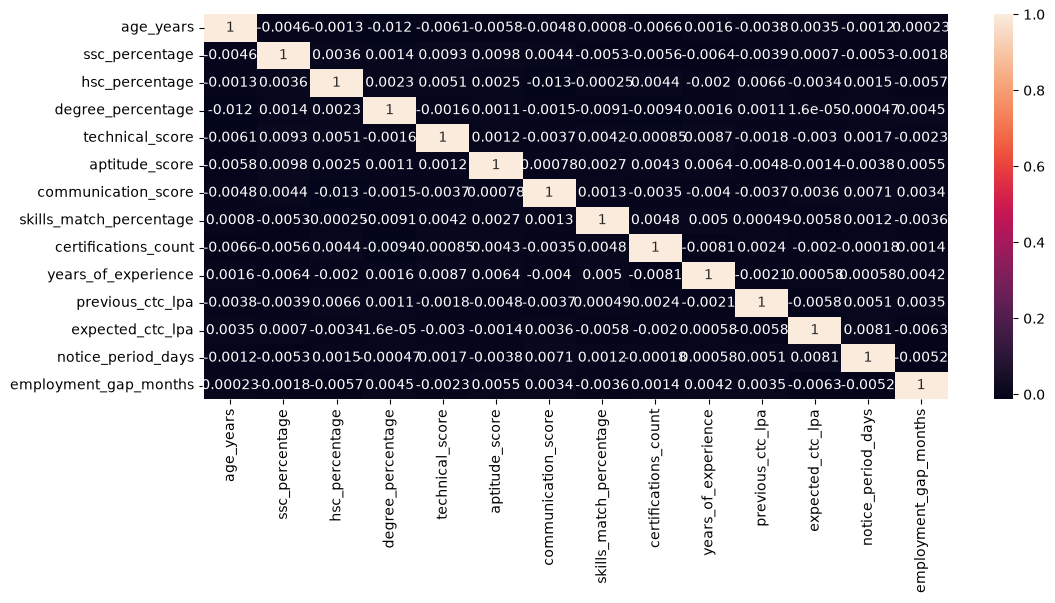

In [61]:
plt.figure(figsize=(12,5))
sns.heatmap(corr_detail,annot=True)
plt.show()

In [62]:
df1.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status'],
      dtype='str')

*#2 Interview Score vs Job Acceptance :(interview score--> tech,aptitude,comm scores)*

In [63]:
df1['interview_Score']=round(df1[['technical_score','aptitude_score','communication_score']].mean(axis=1))

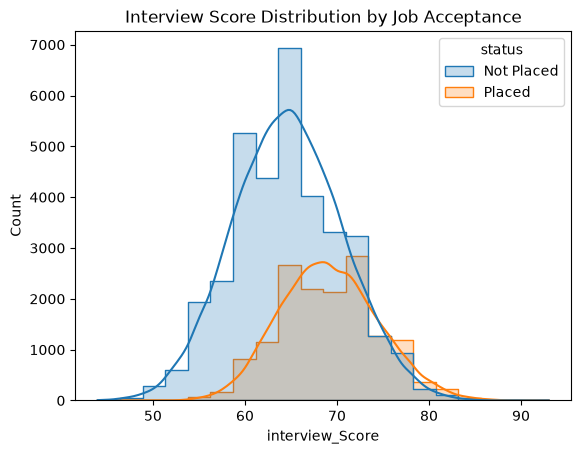

In [64]:
#1. Interview Score vs job Acceptance(both accept & declined):
sns.histplot(
    data=df1,
    x='interview_Score',
    hue='status',
    bins=20,
    kde=True,
    element='step'
)

plt.title('Interview Score Distribution by Job Acceptance')
plt.show()

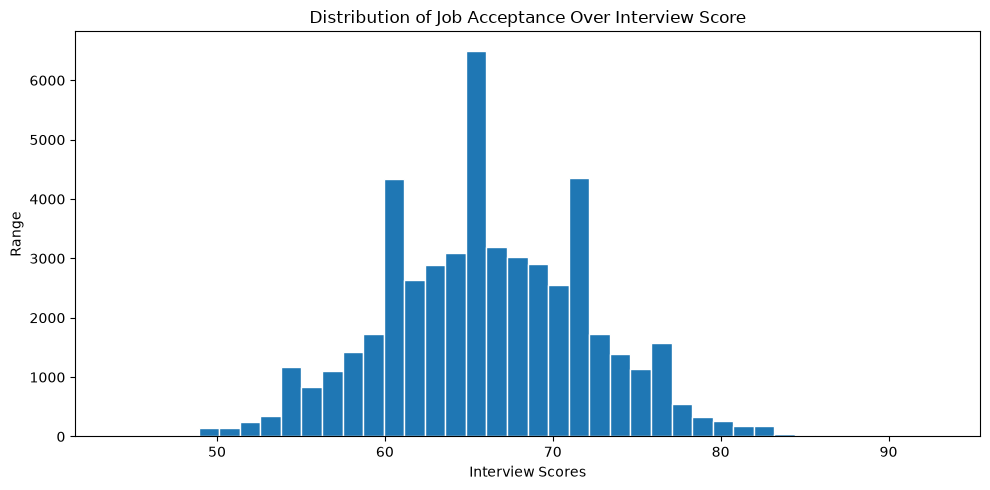

In [65]:
#2. Interview Score distribution
i_s=df1['interview_Score'].plot(kind='hist',bins=40,figsize=(10,5),
                             title='Distribution of Job Acceptance Over Interview Score',
                             edgecolor='white')
i_s.set_xlabel('Interview Scores')
i_s.set_ylabel('Range')
plt.tight_layout()
plt.show()

*#3 Company Tier vs Acceptance Rate:*

In [66]:
df1['company_tier']=df1['company_tier'].str.strip()

In [67]:
# Total Count of candidates based on company_tier:
df1.groupby('company_tier')['status'].count()

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: status, dtype: int64

In [68]:
# Acceptance Rate = acc/tot cand * 100
tot_cnt=df1.groupby('company_tier')['status'].count()
tot_cnt

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: status, dtype: int64

In [69]:
# Apply .apply & lambda to get accecpted candidates:
acceptance_rate=df1.groupby('company_tier')['status'].apply(lambda x:round(x=='Placed').mean()*100).rename("acceptance_rate_%")
acceptance_rate=round(acceptance_rate,2)
acceptance_rate

company_tier
Tier 1    29.95
Tier 2    30.43
Tier 3    30.54
Name: acceptance_rate_%, dtype: float64

In [70]:
df1['company_tier'].value_counts()

company_tier
Tier 1    19358
Tier 2    18534
Tier 3    12232
Name: count, dtype: int64

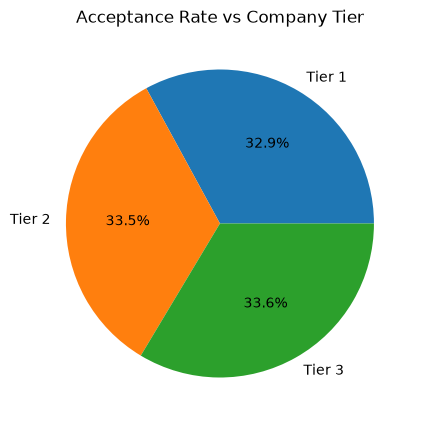

In [71]:
# Pie Chart:
acceptance_rate=df1.groupby('company_tier')['status'].apply(lambda x:round(x=='Placed').mean()*100).rename("acceptance_rate_%")
acceptance_rate=round(acceptance_rate,2)

plt.figure(figsize=(12,5))
plt.pie(x=acceptance_rate,
        labels=df1['company_tier'].value_counts().index,
        autopct='%1.1f%%')
plt.title('Acceptance Rate vs Company Tier')
plt.show()

*#4 Experience vs Placement Probability:*

In [90]:
#Placement Probability: (PROCESS is in FEATURE ENGG RUN that first)
df1['placement_prob']=round((df1['academic_score']*0.15 + df1['interview_Score']*0.65 + df1['skills_match_percentage']*0.20),2)

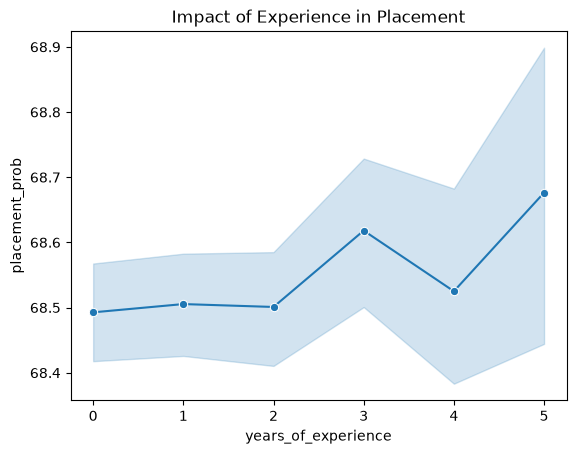

In [91]:
sns.lineplot(
                data=df1,
                x='years_of_experience',
                y='placement_prob',
                marker='o'
)
plt.title('Impact of Experience in Placement')
plt.show()

*#5 Competition level vs Job Acceptance:*

In [73]:
df1['competition_level'].value_counts()

competition_level
Low       20891
Medium    19165
High      10068
Name: count, dtype: int64

# Without Using GROUPBY

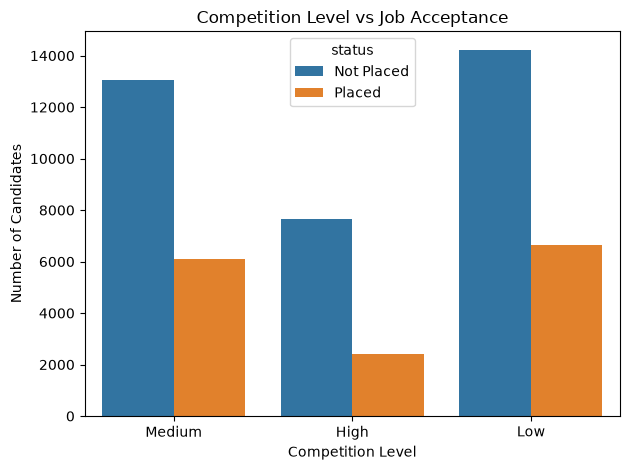

In [74]:
# COUNTPLOT

sns.countplot(
    data=df1,
    x='competition_level',
    hue='status'
)

plt.title('Competition Level vs Job Acceptance')
plt.xlabel('Competition Level')
plt.ylabel('Number of Candidates')
plt.tight_layout()
plt.show()

# USING GROUPBY:

In [75]:
# USING GROUPBY:

comp_job1=(df1.groupby(['competition_level','status'])
           .size()
           .unstack(fill_value=0)
           #.reset_index(name='Tot_Candidate')
           )
print(comp_job1)

status             Not Placed  Placed
competition_level                    
High                     7672    2396
Low                     14233    6658
Medium                  13045    6120


In [76]:
df1[['competition_level','status']].value_counts() # THE GROUPBY & VALU COUNT GIVES SAME OUTPUT:

competition_level  status    
Low                Not Placed    14233
Medium             Not Placed    13045
High               Not Placed     7672
Low                Placed         6658
Medium             Placed         6120
High               Placed         2396
Name: count, dtype: int64

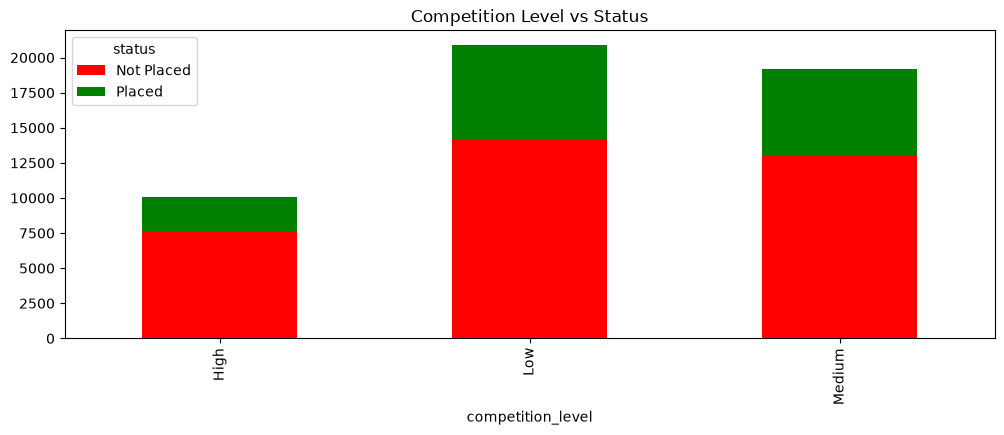

In [77]:
# PLOT USING GROUPBY:
# STACKED BAR:
comp_job1.plot(kind='bar',stacked=True,figsize=(12,4),color=['red','green'])
plt.title('Competition Level vs Status')
plt.show()

*#6 Skills Match Percentage Impact on Placement:*

In [78]:
df1[['skills_match_percentage','status']].value_counts()

skills_match_percentage  status    
100.000000               Not Placed    412
                         Placed        399
45.000000                Not Placed    391
79.548913                Not Placed      2
61.135298                Not Placed      2
                                      ... 
61.997596                Not Placed      1
77.767081                Not Placed      1
54.749371                Not Placed      1
92.333175                Not Placed      1
52.115751                Not Placed      1
Name: count, Length: 48805, dtype: int64

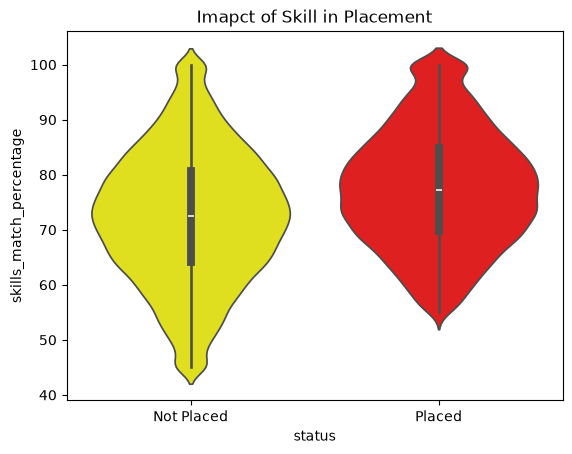

In [79]:
# VIOLIN CHART:

sns.violinplot(data=df1,
               x='status',
               y='skills_match_percentage',
               hue='status',
               palette={'Placed':'red',
                        'Not Placed':'yellow'})
plt.title('Imapct of Skill in Placement')
plt.show()

*#7 Notice Period vs Job Acceptance:*

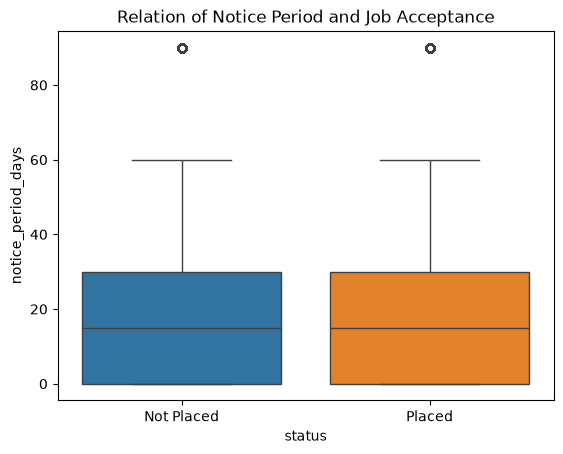

In [80]:
sns.boxplot(data=df1,
            x='status',
            y='notice_period_days',
            hue='status')
plt.title("Relation of Notice Period and Job Acceptance")
plt.show()

# 7. Feature Extraction:

In [81]:
df1.head(15)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,interview_Score
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15,No,18.0,Not Willing,Not Placed,71.0
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,Yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0,No,0.0,Not Willing,Not Placed,63.0
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0,No,3.0,Not Willing,Placed,70.0
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0,Yes,6.0,Not Willing,Not Placed,65.0
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0,No,3.0,Willing,Not Placed,65.0
5,33,Female,60.641768,66.151843,78.203455,Others,85.063940,46.293090,47.638858,78.307411,1,Yes,1,Not Willing,Relevant,4.918530,3.000000,Tier 2,Not Matched,Low,Not Required,60,No,0.0,Not Willing,Placed,60.0
6,25,Female,78.224191,69.578282,79.870959,Mechanical,85.168067,47.188328,70.348778,79.935956,1,Yes,1,Not Willing,Relevant,7.946910,7.114406,Tier 2,Matched,Low,Not Required,0,No,0.0,Not Willing,Placed,68.0
7,27,Female,69.978358,69.111350,75.430679,Others,75.672196,56.391743,76.383155,77.546335,0,Yes,3,Willing,Relevant,8.056013,3.103734,Tier 1,Matched,Medium,Not Required,0,No,0.0,Not Willing,Placed,69.0
8,30,Female,69.535754,78.757507,79.757543,Mechanical,78.282823,62.647484,81.629846,67.931840,3,Yes,2,Not Willing,Relevant,4.190206,3.000000,Tier 3,Matched,Low,Not Required,20,No,0.0,Not Willing,Placed,74.0
9,23,Female,70.972461,78.101606,72.767897,Mechanical,54.554258,61.055905,59.567957,95.125145,0,No,2,Willing,Relevant,5.925225,3.091102,Tier 1,Not Matched,High,Required,0,No,0.0,Willing,Not Placed,58.0


In [82]:
# 1.Experience category (Fresher / Junior / Senior)

cond=[
    (df1.years_of_experience>= 4),
    (df1.years_of_experience>=1) &( df1.years_of_experience<4),
    (df1.years_of_experience == 0)
]

df1['experience_cat']=np.select(cond,['Senior','Junier','Fresher'],
                                     default='None')

In [83]:
# 2.Academic performance bands
# take the percentage of academic marks(SSLC<HSC<DEGREE)

df1['academic_score']=round(df1[['ssc_percentage','hsc_percentage','degree_percentage']].mean(axis=1),2)


In [84]:
cond1=[
        (df1.academic_score >= 90),
        (df1.academic_score >= 70) & (df1.academic_score < 90),
        (df1.academic_score >=50) & (df1.academic_score < 70),
        (df1.academic_score >=40) & (df1.academic_score < 50),
        (df1.academic_score < 40) 
       ]
df1['academic_cat']=np.select(cond1,['Outstanding','Excellent','Good','Fair','Poor',],
                              default='None')

In [85]:
# 3.Skills Match Level (Low / Medium / High): (range from 45 to 100)

cond2=[
        (df1.skills_match_percentage >= 80),
        (df1.skills_match_percentage >= 60) & (df1.skills_match_percentage < 80),
        (df1.skills_match_percentage >=40) & (df1.skills_match_percentage < 60)
]

df1['skill_cat']=np.select(cond2,['High','Medium','Low'],
                           default='None')

In [86]:
# 4.Interview Performance Category:

cond3=[
    df1['interview_Score'] >= 80,
    df1['interview_Score'].between(70,80),
    df1['interview_Score'].between(50,70),
    df1['interview_Score'].between(40,50)
]

df1['interview_Score_cat']=np.select(cond3,['Excellent','Good','Average','Poor'],
                                     default='None')

#To find probability we need to take the 5 feature that connect with target <br>
#i.e., take certain percentage in each score like <br>
#academic=15%, interview score = 65% , skill=20% <br>
#Create a derived column using these values by aggregation <br>
#For aggr calling bracket must use <br>
<br>
#Then apply numpy to select condition

In [87]:
# 5. Placement Probability Score:
# CREATE A COL USING AGGREGATION:
df1['placement_prob']=round((df1['academic_score']*0.15 + df1['interview_Score']*0.65 + df1['skills_match_percentage']*0.20),2)

In [88]:
# Apply condition:

cond5=[
    (df1['placement_prob'] >= 75),
    (df1['placement_prob']).between(60,75),
    (df1['placement_prob']).between(40,60)
]

df1['placement_cat']=np.select(cond5,['High','Moderate','Low'],
                                default='None')

In [89]:
df1['placement_cat'].value_counts()

placement_cat
Moderate    44234
High         4184
Low          1706
Name: count, dtype: int64

*# SAVE the FEATURED DATAFRAME TO CSV*

In [92]:
df1.to_csv(r"D:\DS Course\Job_P3\placement_clean_feat_data.csv",
           index=False,
               encoding="utf-8"
           )
print(" Featured Data Saved Sucessfully")

 Featured Data Saved Sucessfully


In [93]:
df1.columns[df1.isna().any()]

Index([], dtype='str')

# 7. Split Train & Test

In [94]:
df2=df1.copy()
print(df1.shape)
print(df2.shape)

(50124, 34)
(50124, 34)


In [95]:
# Split test train : 
#Step 1: IMPORT PACKAGE:

from sklearn.model_selection import train_test_split

In [96]:
# SEPARATE FEATURE & TARGET:
X = df2.drop('status', axis=1)
y = df2['status']

In [97]:
# Test Train Split:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [98]:
# Num and Cat cols split:
num_cols = X_train.select_dtypes(include=np.number).columns

cat_cols = X_train.select_dtypes(
    include=['str', 'category', 'bool']
).columns

print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'interview_Score', 'academic_score', 'placement_prob']
Categorical: ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'experience_cat', 'academic_cat', 'skill_cat', 'interview_Score_cat', 'placement_cat']


# 8. Encoding:(One-Hot / Label)

# AS df2 is a cleaned data the inde might changed as some of the rows are dropped
# so after concat for that absent rows also it attain values and excess rows are formed 
# go before encoding and reset the index in duplicate removing itself

In [99]:
# One-Hot Encodeing:
# import the package:
from sklearn.preprocessing import OneHotEncoder

In [100]:
# Step 1: Apply ONE HOT ENCODING for train and test:

one_enc = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)

X_train_enc = one_enc.fit_transform(X_train[cat_cols])

X_test_enc = one_enc.transform(X_test[cat_cols])

In [101]:
X_train_enc

array([[1., 0., 0., ..., 0., 0., 1.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 0., 1.],
       ...,
       [1., 0., 1., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 1.]], shape=(40099, 27))

In [102]:
# Step 2: Convert to Dataframe:

enc_cols = one_enc.get_feature_names_out(cat_cols)

df_train_enc = pd.DataFrame(
    X_train_enc,
    columns=enc_cols,
    index=X_train.index
)

df_test_enc = pd.DataFrame(
    X_test_enc,
    columns=enc_cols,
    index=X_test.index
)

In [103]:
df_train_enc.head(3)

,gender_Male,degree_specialization_Electronics,degree_specialization_Information Technology,degree_specialization_Mechanical,degree_specialization_Others,internship_experience_Yes,career_switch_willingness_Willing,relevant_experience_Relevant,company_tier_Tier 2,company_tier_Tier 3,job_role_match_Not Matched,competition_level_Low,competition_level_Medium,bond_requirement_Required,layoff_history_Yes,relocation_willingness_Willing,experience_cat_Junier,experience_cat_Senior,academic_cat_Good,academic_cat_Outstanding,skill_cat_Low,skill_cat_Medium,interview_Score_cat_Excellent,interview_Score_cat_Good,interview_Score_cat_Poor,placement_cat_Low,placement_cat_Moderate
43124,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
26110,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
11576,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [104]:
df_test_enc.head(3)

,gender_Male,degree_specialization_Electronics,degree_specialization_Information Technology,degree_specialization_Mechanical,degree_specialization_Others,internship_experience_Yes,career_switch_willingness_Willing,relevant_experience_Relevant,company_tier_Tier 2,company_tier_Tier 3,job_role_match_Not Matched,competition_level_Low,competition_level_Medium,bond_requirement_Required,layoff_history_Yes,relocation_willingness_Willing,experience_cat_Junier,experience_cat_Senior,academic_cat_Good,academic_cat_Outstanding,skill_cat_Low,skill_cat_Medium,interview_Score_cat_Excellent,interview_Score_cat_Good,interview_Score_cat_Poor,placement_cat_Low,placement_cat_Moderate
30313,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
13902,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
509,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [105]:
# Step 3: CONCAT 
X_train_final = pd.concat(
    [X_train[num_cols], df_train_enc],
    axis=1
)

X_test_final = pd.concat(
    [X_test[num_cols], df_test_enc],
    axis=1
)

# 9. Scaling

In [106]:
# IMPORT Scaling package --> Standard Scalar

from sklearn.preprocessing import StandardScaler

In [107]:
# Step 1:  INITIALIZE Scaling for train & test

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)

X_test_scaled = scaler.transform(X_test_final)

In [108]:
# Step 2: Convert to DataFrame:

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_final.columns,
    index=X_train_final.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_final.columns,
    index=X_test_final.index
)

In [109]:
X_train_scaled.head()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months,interview_Score,academic_score,placement_prob,gender_Male,degree_specialization_Electronics,degree_specialization_Information Technology,degree_specialization_Mechanical,degree_specialization_Others,internship_experience_Yes,career_switch_willingness_Willing,relevant_experience_Relevant,company_tier_Tier 2,company_tier_Tier 3,job_role_match_Not Matched,competition_level_Low,competition_level_Medium,bond_requirement_Required,layoff_history_Yes,relocation_willingness_Willing,experience_cat_Junier,experience_cat_Senior,academic_cat_Good,academic_cat_Outstanding,skill_cat_Low,skill_cat_Medium,interview_Score_cat_Excellent,interview_Score_cat_Good,interview_Score_cat_Poor,placement_cat_Low,placement_cat_Moderate
43124,-1.607765,-2.569720,-1.476038,-0.143658,-0.739999,-0.332256,-0.251318,-0.141477,-0.336381,-0.360295,-1.799733,0.026790,-0.006123,-0.679926,-0.822985,-2.488252,-1.117577,1.006078,-0.500125,-0.499111,2.006382,-0.504796,1.046649,-0.626128,0.696921,1.308698,-0.569489,-0.54766,-0.844291,1.267828,-0.531634,-0.351566,-1.288329,0.813801,-0.334998,1.453961,-0.004994,-0.374710,0.872512,-0.119009,-0.609752,-0.050993,-0.187724,0.363720
26110,1.121912,-0.005596,0.162819,-1.812390,-0.836680,-1.663497,-1.121764,-2.179123,0.505391,1.820894,1.042610,-0.556536,-0.823160,-0.679926,-1.967577,-0.872483,-2.892707,1.006078,-0.500125,-0.499111,-0.498410,1.980998,1.046649,-0.626128,-1.434884,-0.764118,1.755962,-0.54766,1.184426,-0.788751,-0.531634,-0.351566,0.776200,-1.228801,2.985092,1.453961,-0.004994,2.668734,-1.146116,-0.119009,-0.609752,-0.050993,5.326965,-2.749367
11576,-1.607765,-0.443106,0.521587,0.588205,-1.455954,0.519406,1.732347,-1.573387,0.505391,1.093831,-1.152640,1.624093,0.402396,0.000900,0.321607,0.358907,-0.469547,1.006078,-0.500125,-0.499111,2.006382,-0.504796,-0.955430,-0.626128,0.696921,-0.764118,1.755962,-0.54766,-0.844291,1.267828,1.880994,-0.351566,0.776200,0.813801,-0.334998,-0.687777,-0.004994,2.668734,-1.146116,-0.119009,-0.609752,-0.050993,-0.187724,0.363720
45273,1.121912,-1.318291,0.458641,0.795818,0.269295,-0.838222,0.721419,-0.946769,1.347163,-0.360295,-0.594986,1.118024,-0.823160,-0.679926,0.158094,-0.089918,-0.356195,1.006078,-0.500125,-0.499111,-0.498410,1.980998,1.046649,-0.626128,0.696921,1.308698,-0.569489,-0.54766,1.184426,-0.788751,-0.531634,-0.351566,0.776200,0.813801,-0.334998,-0.687777,-0.004994,-0.374710,0.872512,-0.119009,-0.609752,-0.050993,-0.187724,0.363720
32035,-1.111460,0.102687,1.214031,-0.595913,1.737814,-0.164323,-0.139650,0.096226,-0.336381,-0.360295,0.177900,0.690772,2.853509,3.405031,0.975659,0.464783,0.942002,-0.993958,-0.500125,-0.499111,-0.498410,1.980998,1.046649,-0.626128,-1.434884,-0.764118,-0.569489,-0.54766,-0.844291,-0.788751,-0.531634,-0.351566,0.776200,0.813801,-0.334998,-0.687777,-0.004994,-0.374710,0.872512,-0.119009,1.640012,-0.050993,-0.187724,0.363720


In [110]:
X_test_scaled.head()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months,interview_Score,academic_score,placement_prob,gender_Male,degree_specialization_Electronics,degree_specialization_Information Technology,degree_specialization_Mechanical,degree_specialization_Others,internship_experience_Yes,career_switch_willingness_Willing,relevant_experience_Relevant,company_tier_Tier 2,company_tier_Tier 3,job_role_match_Not Matched,competition_level_Low,competition_level_Medium,bond_requirement_Required,layoff_history_Yes,relocation_willingness_Willing,experience_cat_Junier,experience_cat_Senior,academic_cat_Good,academic_cat_Outstanding,skill_cat_Low,skill_cat_Medium,interview_Score_cat_Excellent,interview_Score_cat_Good,interview_Score_cat_Poor,placement_cat_Low,placement_cat_Moderate
30313,-0.863307,-0.765992,-0.065042,-1.109361,1.599249,0.128041,-0.477504,-0.823526,-0.336381,-0.360295,0.925888,0.711440,0.402396,-0.679926,0.812146,-1.086538,0.122876,1.006078,-0.500125,-0.499111,-0.49841,-0.504796,-0.955430,-0.626128,0.696921,1.308698,-0.569489,-0.547660,-0.844291,1.267828,-0.531634,2.844412,0.776200,0.813801,-0.334998,1.453961,-0.004994,-0.37471,0.872512,-0.119009,1.640012,-0.050993,-0.187724,0.36372
13902,-0.367003,-0.786375,-1.458927,0.251008,0.086502,-0.415445,-0.804459,2.209523,-0.336381,-0.360295,0.635175,-0.122830,-0.823160,0.681726,-0.659472,-1.203923,0.385937,1.006078,-0.500125,-0.499111,-0.49841,-0.504796,-0.955430,1.597117,0.696921,-0.764118,1.755962,-0.547660,-0.844291,1.267828,-0.531634,-0.351566,0.776200,0.813801,-0.334998,1.453961,-0.004994,-0.37471,-1.146116,-0.119009,-0.609752,-0.050993,-0.187724,0.36372
509,1.121912,-0.068647,-0.748234,-0.631379,-2.093240,-0.372969,-0.063623,0.733854,0.505391,-1.087358,-0.123509,0.830811,0.402396,-0.679926,-1.640550,-0.824148,-1.138964,-0.993958,-0.500125,-0.499111,-0.49841,-0.504796,-0.955430,-0.626128,-1.434884,-0.764118,1.755962,-0.547660,-0.844291,-0.788751,-0.531634,-0.351566,-1.288329,-1.228801,-0.334998,1.453961,-0.004994,-0.37471,-1.146116,-0.119009,-0.609752,-0.050993,-0.187724,0.36372
45908,-1.359612,-0.375904,-1.207836,0.943764,0.112315,0.941470,-0.546660,0.901074,-0.336381,2.547956,-1.421608,-0.890258,0.402396,-0.679926,0.321607,-0.439771,0.666109,-0.993958,1.999501,-0.499111,-0.49841,-0.504796,1.046649,-0.626128,0.696921,-0.764118,-0.569489,-0.547660,1.184426,-0.788751,-0.531634,-0.351566,-1.288329,-1.228801,2.985092,-0.687777,-0.004994,-0.37471,-1.146116,-0.119009,-0.609752,-0.050993,-0.187724,0.36372
24473,-1.359612,1.461382,1.159322,-0.015499,0.396741,0.707992,0.680268,0.399329,-0.336381,-1.087358,1.408758,0.936390,2.853509,2.043379,0.975659,1.553471,1.247838,1.006078,-0.500125,-0.499111,-0.49841,1.980998,1.046649,-0.626128,0.696921,-0.764118,1.755962,1.825949,-0.844291,-0.788751,-0.531634,-0.351566,0.776200,-1.228801,-0.334998,-0.687777,-0.004994,-0.37471,0.872512,-0.119009,1.640012,-0.050993,-0.187724,0.36372


# 10. Model Training Testing:

# 10.1 Logistic Regression:

In [111]:
# Step 1: IMPORT pkg & INITIALIZE the model:

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

In [112]:
# Step 2: Model Training:

lr.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [113]:
# Step 3: Prediction:

y_pred_lr = lr.predict(X_test_scaled)

In [114]:
# Step 4: Evaluation 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

lr_acc = accuracy_score(y_test, y_pred_lr)

lr_pre = precision_score(
    y_test, y_pred_lr,
    average='weighted'
)

lr_rec = recall_score(
    y_test, y_pred_lr,
    average='weighted'
)

lr_f1 = f1_score(
    y_test, y_pred_lr,
    average='weighted'
)

print("Logistic Regression Evaluation")
print("Accuracy :", lr_acc)
print("Precision:", lr_pre)
print("Recall   :", lr_rec)
print("F1 Score :", lr_f1)

Logistic Regression Evaluation
Accuracy : 0.8697256857855361
Precision: 0.8683925209688533
Recall   : 0.8697256857855361
F1 Score : 0.8688869819994547


In [115]:
# Step 5: Classification Report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

  Not Placed       0.90      0.92      0.91      6990
      Placed       0.80      0.76      0.78      3035

    accuracy                           0.87     10025
   macro avg       0.85      0.84      0.84     10025
weighted avg       0.87      0.87      0.87     10025



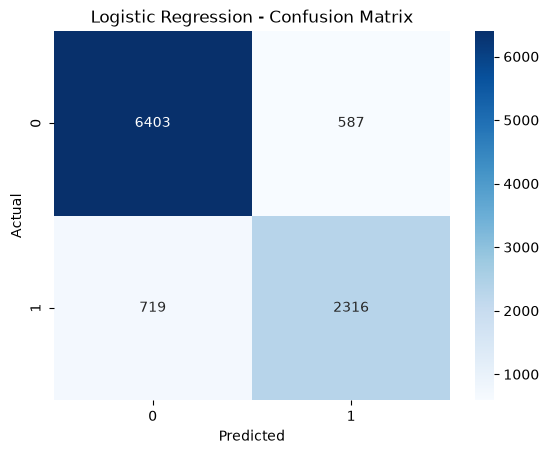

In [116]:
# Step 6: Confusion Matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
# Step 7: ROC-AUC Score:

y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

positive_class = lr.classes_[1]
y_binary = (y_test == positive_class).astype(int)

lr_auc = roc_auc_score(y_binary, y_prob_lr)

print("ROC-AUC Score:", lr_auc)

ROC-AUC Score: 0.94106864831614


# 10.2 Decision Tree:

In [118]:
# Step 1: IMPORT package:

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

In [119]:
# Step 2: Apply Model

dt.fit(X_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [120]:
# Step 3: Predicted o/p:

y_pred_dt = dt.predict(X_test_scaled)

In [121]:
# Step 4: Evaluation 

dt_acc = accuracy_score(y_test, y_pred_dt)

dt_pre = precision_score(
    y_test, y_pred_dt,
    average='weighted'
)

dt_rec = recall_score(
    y_test, y_pred_dt,
    average='weighted'
)

dt_f1 = f1_score(
    y_test, y_pred_dt,
    average='weighted'
)

print("Decision Tree Evaluation")
print("Accuracy :", dt_acc)
print("Precision:", dt_pre)
print("Recall   :", dt_rec)
print("F1 Score :", dt_f1)


Decision Tree Evaluation
Accuracy : 0.8482793017456359
Precision: 0.8459287420649809
Recall   : 0.8482793017456359
F1 Score : 0.8466752807242119


In [122]:
# Step 5: Classification Report:

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

  Not Placed       0.88      0.91      0.89      6990
      Placed       0.77      0.71      0.74      3035

    accuracy                           0.85     10025
   macro avg       0.82      0.81      0.82     10025
weighted avg       0.85      0.85      0.85     10025



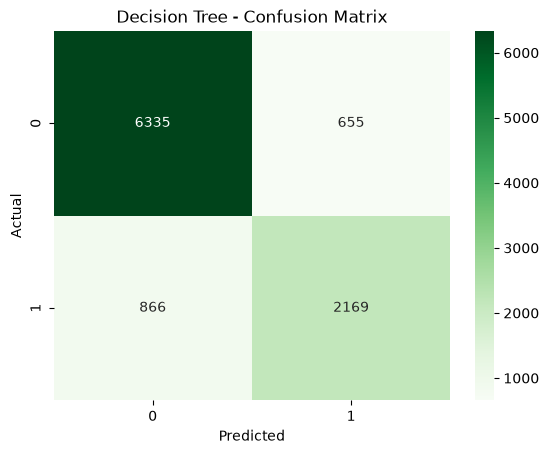

In [123]:
# Confusion Matrix:

cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
# Step 7: ROC-AUC Score:
y_prob_dt = dt.predict_proba(X_test_scaled)[:, 1]

positive_class = dt.classes_[1]
y_binary = (y_test == positive_class).astype(int)

dt_auc = roc_auc_score(y_binary, y_prob_dt)

print("ROC-AUC Score:", dt_auc)

# 10.3 Random Forest:

In [124]:
# Step 1: Import:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [125]:
# Step 2: Model Train:
rf.fit(X_train_scaled, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [126]:
# Step 3: Predict:
y_pred_rf = rf.predict(X_test_scaled)

In [127]:
# Step 4: Evaluation:

rf_acc = accuracy_score(y_test, y_pred_rf)

rf_pre = precision_score(
    y_test, y_pred_rf,
    average='weighted'
)

rf_rec = recall_score(
    y_test, y_pred_rf,
    average='weighted'
)

rf_f1 = f1_score(
    y_test, y_pred_rf,
    average='weighted'
)

print("Random Forest Evaluation")
print("Accuracy :", rf_acc)
print("Precision:", rf_pre)
print("Recall   :", rf_rec)
print("F1 Score :", rf_f1)

Random Forest Evaluation
Accuracy : 0.8649376558603491
Precision: 0.8633578265408148
Recall   : 0.8649376558603491
F1 Score : 0.8603277815672874


In [128]:
# Step 5 : Classification Report:

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

  Not Placed       0.87      0.95      0.91      6990
      Placed       0.84      0.68      0.75      3035

    accuracy                           0.86     10025
   macro avg       0.86      0.81      0.83     10025
weighted avg       0.86      0.86      0.86     10025



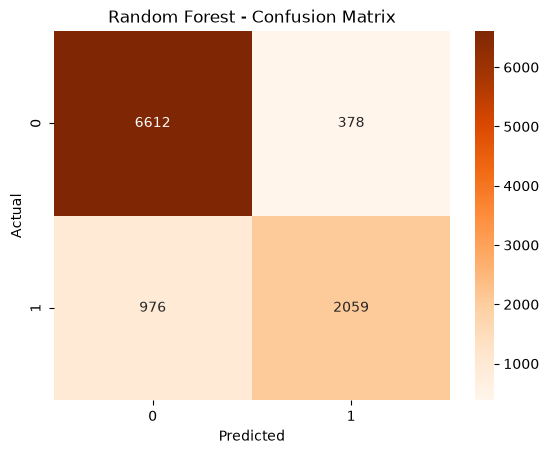

In [129]:
# Step 6 : Confusion Matrix:

cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
# Step 7: ROC-AUC Score:
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

positive_class = rf.classes_[1]
y_binary = (y_test == positive_class).astype(int)

rf_auc = roc_auc_score(y_binary, y_prob_rf)

print("ROC-AUC Score:", rf_auc)

*# Convert the results to dataframe:*

In [130]:
report={
    "Model":[ "Logistic Regression Evaluation","Decision Tree","Random Forest"],
    "Accuracy": [lr_acc,dt_acc,rf_acc],
    "Precision": [lr_pre,dt_pre,rf_pre],
    "Recall": [lr_rec,dt_rec,rf_rec],
    "F1 Score": [lr_f1,dt_f1,rf_f1]
}
report_df=pd.DataFrame(report)
report_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression Evaluation,0.869726,0.868393,0.869726,0.868887
1,Decision Tree,0.848279,0.845929,0.848279,0.846675
2,Random Forest,0.864938,0.863358,0.864938,0.860328


*# Save the DataFrame*

In [131]:
report_df.to_csv(r"D:\DS Course\Job_P3\classify_report.csv",
           index=False,
               encoding="utf-8"
           )
print(" Classification Report Saved Sucessfully")

 Classification Report Saved Sucessfully


# 11. EDA & ML Analysis

In [132]:
df1.head(5)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,interview_Score,experience_cat,academic_score,academic_cat,skill_cat,interview_Score_cat,placement_prob,placement_cat
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15,No,18.0,Not Willing,Not Placed,71.0,Junier,74.92,Excellent,Medium,Good,73.30,Moderate
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,Yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0,No,0.0,Not Willing,Not Placed,63.0,Fresher,68.65,Good,Medium,Average,65.91,Moderate
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,1,Yes,1,Willing,Relevant,5.801817,5.476839,Tier 3,Not Matched,Low,Not Required,0,No,3.0,Not Willing,Placed,70.0,Junier,77.64,Excellent,Medium,Good,72.24,Moderate
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,2,No,0,Not Willing,Relevant,2.129805,9.980580,Tier 2,Matched,Low,Not Required,0,Yes,6.0,Not Willing,Not Placed,65.0,Fresher,75.33,Excellent,Medium,Average,68.28,Moderate
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,1,No,0,Willing,Not Relevant,7.948314,8.921233,Tier 2,Matched,Medium,Not Required,0,No,3.0,Willing,Not Placed,65.0,Fresher,69.02,Good,High,Average,70.40,Moderate


*11.1 Candidate Performance Analysis*

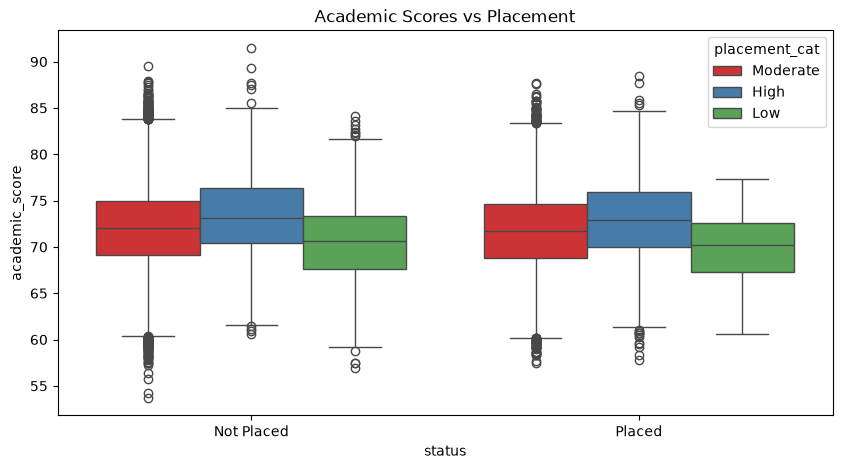

In [133]:
# Academic Scores vs Placement Outcome:
# BOXPLOT:
plt.figure(figsize=(10,5))
sns.boxplot(data=df1,
            x='status',
            y='academic_score',
            palette='Set1',
            hue='placement_cat'
            )
plt.title('Academic Scores vs Placement')
plt.show()


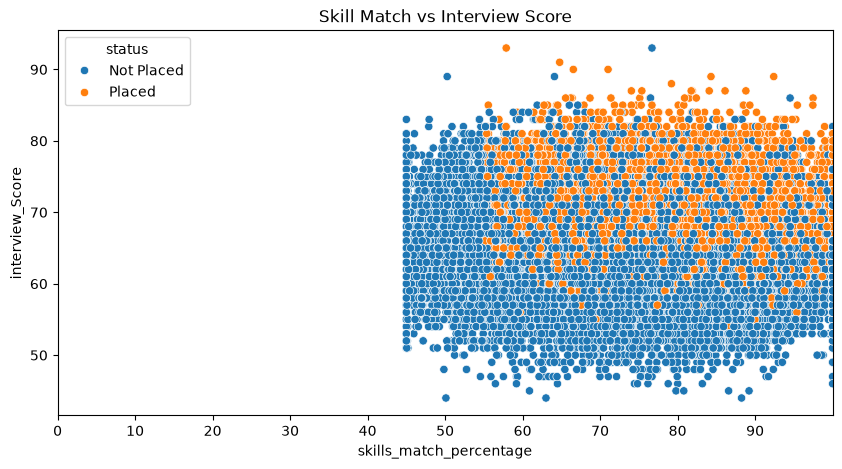

In [134]:
# Skills match vs interview performance
# Scatter Plot

plt.figure(figsize=(10,5))
sns.scatterplot(data=df1,
                x='skills_match_percentage',
                y='interview_Score',
                hue='status',
                color='steelblue')
plt.xlim(0,100)
plt.xticks(range(0,100,10))
plt.title('Skill Match vs Interview Score')
plt.show()

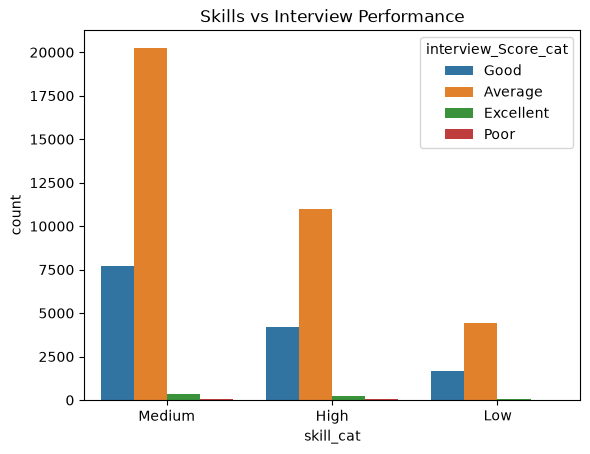

In [135]:
# COUNT PLOT
sns.countplot(data=df1, x= 'skill_cat',
              hue='interview_Score_cat')
plt.title('Skills vs Interview Performance')
plt.show()

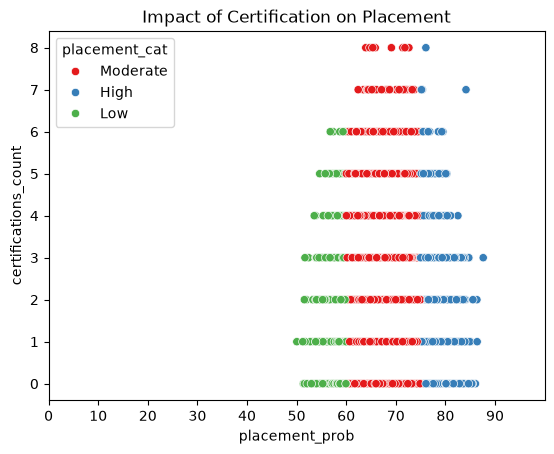

In [137]:
# Certification impact on job acceptance:
 
sns.scatterplot(data=df1,
                x='placement_prob',
                y='certifications_count',
                hue='placement_cat',
                palette='Set1')
plt.xlim(0,100)
plt.xticks(range(0,100,10))
plt.title('Impact of Certification on Placement')
plt.show()

*# 11.2 Placement & Acceptance Analysis*

In [138]:
# Apply .apply & lambda to get accecpted candidates:
# As to convert acceptance rate in a df .rst_index() is used
# otherwise it show like series that company_tier act as index and acc_rate as values :

acceptance_rate=df1.groupby('company_tier')['status'].apply(lambda x:(x=='Placed').mean()*100).rename("acceptance_rate_%")
acceptance_rate=round(acceptance_rate,2).reset_index()
acceptance_rate

,company_tier,acceptance_rate_%
0,Tier 1,29.95
1,Tier 2,30.43
2,Tier 3,30.54


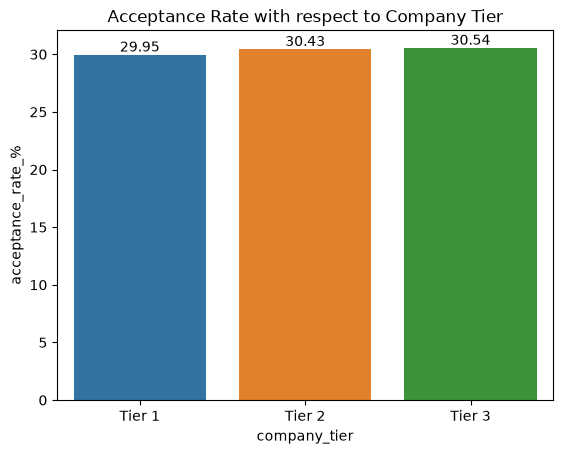

In [139]:
# Acceptance rate by company tier
# BARCHART:
# fmt='%.2f' -- round to 2 decimal point .2 can be changed to any number
ax=sns.barplot(data=acceptance_rate,
               x='company_tier',
               y='acceptance_rate_%',
               hue='company_tier')
for container in ax.containers:
    ax.bar_label(container,fmt="%.2f")
plt.title("Acceptance Rate with respect to Company Tier")
plt.show()

In [140]:
df1['years_of_experience'].value_counts()

years_of_experience
0    14991
1    13535
2     9993
3     6554
4     3556
5     1495
Name: count, dtype: int64

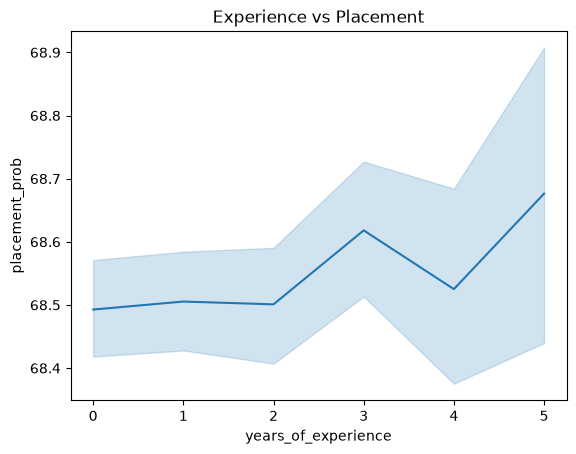

In [141]:
# Experience vs placement success
# LINE CHART
sns.lineplot(data=df1,
             x='years_of_experience',
             y='placement_prob'
             )
plt.title('Experience vs Placement')
plt.show()


*# 11.3 Interview & Evaluation Analysis:*

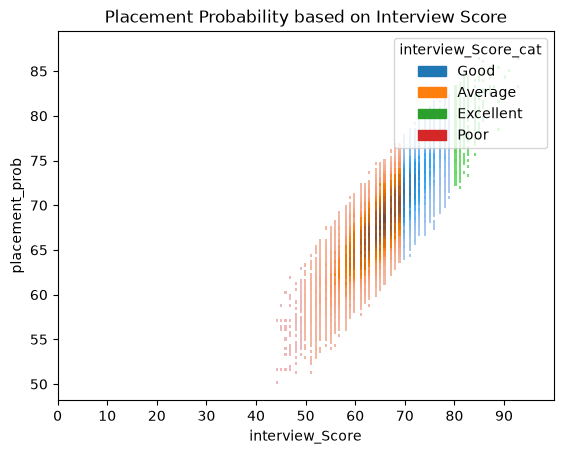

In [142]:
# Interview score vs placement probability
# Histogram:

sns.histplot(data=df1,
             x='interview_Score',
             y='placement_prob',
             hue='interview_Score_cat')

plt.xlim(0,100)
plt.xticks(range(0,100,10))
plt.title('Placement Probability based on Interview Score')
plt.show()


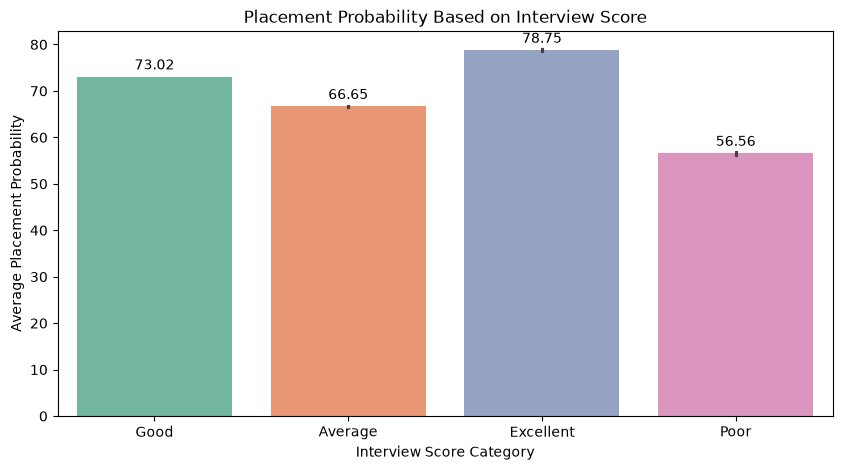

In [143]:
plt.figure(figsize=(10,5))

ax = sns.barplot(data=df1,
                 x='interview_Score_cat',
                 y='placement_prob',
                 hue='interview_Score_cat',
                 palette='Set2')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title('Placement Probability Based on Interview Score')
plt.xlabel('Interview Score Category')
plt.ylabel('Average Placement Probability')

plt.show()

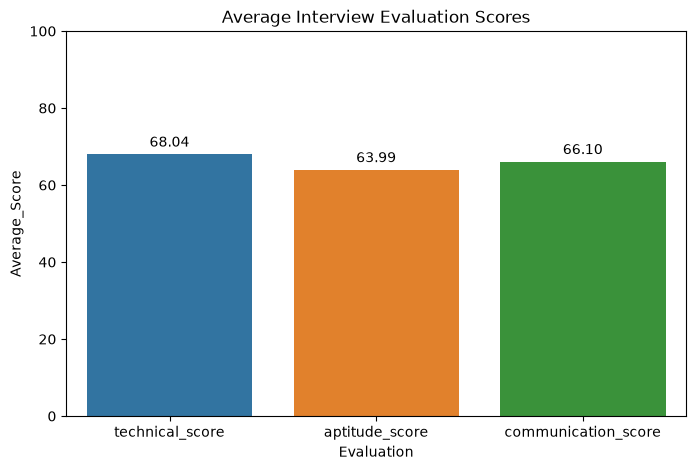

In [144]:
# Employability test score analysis

score_data = df1[['technical_score',
                  'aptitude_score',
                  'communication_score']].mean().reset_index()

score_data.columns = ['Evaluation', 'Average_Score']

plt.figure(figsize=(8,5))
ax=sns.barplot(data=score_data, x='Evaluation', y='Average_Score',hue='Evaluation')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title('Average Interview Evaluation Scores')
plt.ylim(0,100)
plt.show()

In [145]:
df1.columns

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status', 'interview_Score', 'experience_cat', 'academic_score',
       'academic_cat', 'skill_cat', 'interview_Score_cat', 'placement_prob',
       'placement_cat'],
      dtype='str')

In [146]:
df1.head(2)

,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status,interview_Score,experience_cat,academic_score,academic_cat,skill_cat,interview_Score_cat,placement_prob,placement_cat
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,2,No,1,Willing,Relevant,3.530557,5.805850,Tier 3,Not Matched,Medium,Not Required,15,No,18.0,Not Willing,Not Placed,71.0,Junier,74.92,Excellent,Medium,Good,73.30,Moderate
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,1,Yes,0,Not Willing,Relevant,9.858155,10.807739,Tier 1,Matched,High,Required,0,No,0.0,Not Willing,Not Placed,63.0,Fresher,68.65,Good,Medium,Average,65.91,Moderate


In [153]:
"""'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status', 'interview_Score', 'experience_cat', 'academic_score',
       'academic_cat', 'skill_cat', 'interview_Score_cat', 'placement_prob',
       'placement_cat']"""

df1['status'].value_counts()

status
Not Placed    34950
Placed        15174
Name: count, dtype: int64

In [161]:
df1[['relevant_experience','years_of_experience']].value_counts()

relevant_experience  years_of_experience
Relevant             0                      10158
                     1                       9010
                     2                       6794
Not Relevant         0                       4833
                     1                       4525
Relevant             3                       4464
Not Relevant         2                       3199
Relevant             4                       2373
Not Relevant         3                       2090
                     4                       1183
Relevant             5                        997
Not Relevant         5                        498
Name: count, dtype: int64

In [160]:
df1[['notice_period_days','job_role_match','company_tier','competition_level']].value_counts()

notice_period_days  job_role_match  company_tier  competition_level
0                   Matched         Tier 1        Low                  2593
                                    Tier 2        Low                  2534
                                    Tier 1        Medium               2393
                                    Tier 2        Medium               2223
                                    Tier 3        Low                  1650
                                                                       ... 
20                  Not Matched     Tier 3        Low                    30
                                    Tier 2        High                   28
                                    Tier 1        High                   26
90                  Not Matched     Tier 3        High                   24
20                  Not Matched     Tier 3        High                   18
Name: count, Length: 108, dtype: int64

In [183]:
# ASSUMING DROP CANDIDATES:

drop_df=df1[(df1['status']=='Not Placed')&(df1['placement_cat']=='High')&(df1['job_role_match']=='Matched')&(df1['relevant_experience']=='Relevant')&(df1['competition_level']=='High')&(df1['interview_Score_cat']!='Average')][['interview_Score_cat','experience_cat']].value_counts().reset_index(name='no_of_cand')

In [184]:
drop_df

,interview_Score_cat,experience_cat,no_of_cand
0,Good,Fresher,64
1,Good,Junier,47
2,Excellent,Junier,12
3,Excellent,Fresher,5
4,Good,Senior,2


In [185]:
drop_out=drop_df['no_of_cand'].sum()
print(drop_out)

130


***# Acceptance rate:***

In [ ]:
# 1. FIND TOT OFFER
tot_offer=(df1['status']=='Placed').sum() + drop_out
print(tot_offer)

15304


In [ ]:
# 2. Find Acceptance Rate:
# (tot. placed offer/ tot.offer)
accepted_offer= round((df1['status']=='Placed').sum() / tot_offer,2)*100
accepted_offer

np.float64(99.0)

In [193]:
# Find Drop out Rate:
drop_out_offer= round(drop_out/tot_offer,2)*100
drop_out_offer

np.float64(1.0)